--- STATISTIK 5 KONDISI CAHAYA ---
teh_041.png: {'rerata': 168.8, 'simpangan_baku': 36.7, 'min': 59, 'maks': 231, 'persen_gelap': 0.0, 'persen_terang': 3.4}
teh_042.png: {'rerata': 118.9, 'simpangan_baku': 31.1, 'min': 18, 'maks': 159, 'persen_gelap': 3.2, 'persen_terang': 0.0}
teh_043.png: {'rerata': 210.1, 'simpangan_baku': 28.4, 'min': 126, 'maks': 254, 'persen_gelap': 0.0, 'persen_terang': 71.8}
teh_044.png: {'rerata': 154.1, 'simpangan_baku': 15.1, 'min': 105, 'maks': 189, 'persen_gelap': 0.0, 'persen_terang': 0.0}
teh_045.png: {'rerata': 120.0, 'simpangan_baku': 51.3, 'min': 22, 'maks': 229, 'persen_gelap': 2.7, 'persen_terang': 4.4}


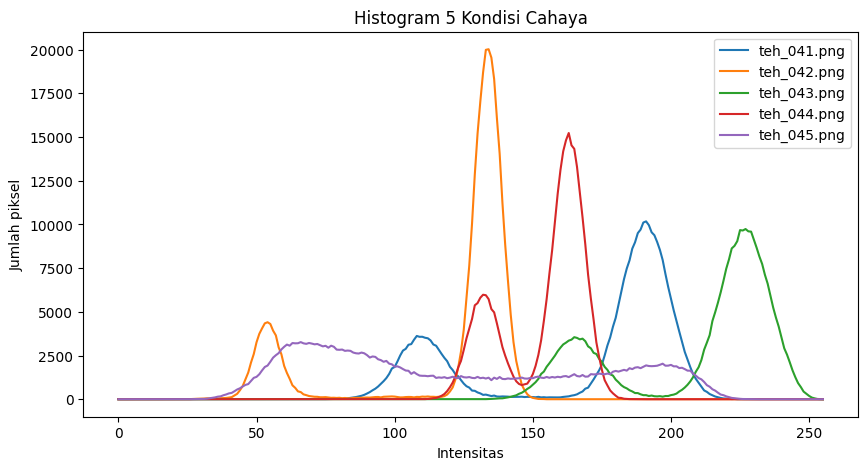


--- EVALUASI KB PER METODE PERBAIKAN (TEH_045) ---
asli       KB = 1.64 | sigma = 51.3
negatif    KB = 1.64 | sigma = 51.3
cerah+50   KB = 1.64 | sigma = 50.8
kontras    KB = 1.64 | sigma = 74.8
regang     KB = 1.69 | sigma = 80.2
gamma0.5   KB = 1.42 | sigma = 37.6
gamma1.8   KB = 2.04 | sigma = 53.4
ekualisasi KB = 1.25 | sigma = 73.4
CLAHE      KB = 2.61 | sigma = 44.3


In [17]:
import os
import sys
if os.getcwd().endswith("notebook"):
    os.chdir("..")
sys.path.append("src")

import cv2
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from utils_cv import baca, kontras_bercak, statistik

# ==========================================
# KODE 3.1: Statistik dan Histogram untuk Diagnosis (Tabel 9)
# ==========================================
print("--- STATISTIK 5 KONDISI CAHAYA ---")
plt.figure(figsize=(10, 5))
citra_uji = ["teh_041.png", "teh_042.png", "teh_043.png", "teh_044.png", "teh_045.png"]

for nama in citra_uji:
    gray = cv2.cvtColor(baca(f"data/sintetis/citra/{nama}"), cv2.COLOR_BGR2GRAY)
    print(f"{nama}:", statistik(gray))
    hist = cv2.calcHist([gray], [0], None, [256], [0, 256])
    plt.plot(hist, label=nama)

plt.xlabel("Intensitas")
plt.ylabel("Jumlah piksel")
plt.legend()
plt.title("Histogram 5 Kondisi Cahaya")
plt.savefig("hasil/b3_histogram_5kondisi.png")
plt.show()

# ==========================================
# KODE 3.2: Operasi Titik, Peregangan, Gamma, Ekualisasi, dan CLAHE (Tabel 10)
# ==========================================
nama = "teh_045.png" # kondisi bayangan
img = baca(f"data/sintetis/citra/{nama}")
md = cv2.imread(f"data/sintetis/mask_daun/{nama}", 0)
mb = cv2.imread(f"data/sintetis/mask_bercak/{nama}", 0)
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)

def gamma_lut(g):
    lut = np.array([255 * (i / 255) ** g for i in range(256)])
    return lut.clip(0, 255).astype(np.uint8)

rmin, rmax = np.percentile(gray, (2, 98))
hasil = {
    "asli": gray,
    "negatif": 255 - gray,
    "cerah+50": cv2.add(gray, 50),
    "kontras": cv2.convertScaleAbs(gray, alpha=1.5, beta=-40),
    "regang": np.clip((gray - rmin) / (rmax - rmin) * 255, 0, 255).astype(np.uint8),
    "gamma0.5": cv2.LUT(gray, gamma_lut(0.5)),
    "gamma1.8": cv2.LUT(gray, gamma_lut(1.8)),
    "ekualisasi": cv2.equalizeHist(gray),
    "CLAHE": cv2.createCLAHE(clipLimit=2.0, tileGridSize=(8, 8)).apply(gray)
}

print("\n--- EVALUASI KB PER METODE PERBAIKAN (TEH_045) ---")
for nm, c in hasil.items():
    print(f"{nm:10s} KB = {kontras_bercak(c, md, mb):.2f} | sigma = {c.std():.1f}")